In [7]:
import numpy as np
import pandas as pd
import torch
from neural_network import SelfOrganizingMaps
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Circle Dataset

In [ ]:
n = 10000
theta = torch.rand(n) * 2 * math.pi          # random angle 0..2π
r = 1.5 + 0.03 * torch.randn(n)              # radius 1.5 + noise
data_circle = torch.stack([r * torch.cos(theta),
                           r * torch.sin(theta)], dim=1)   # (n, 2)

In [9]:
df_c = pd.DataFrame(
    {
        'feature1' : data_circle[:,0],
        'feature2' : data_circle[:,1]
        }
)

<Axes: xlabel='feature1', ylabel='feature2'>

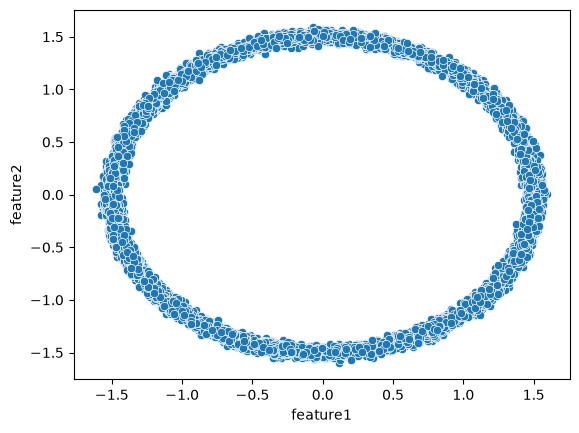

In [10]:
sns.scatterplot(data=df_c, x='feature1', y='feature2')

In [48]:
model = SelfOrganizingMaps(
    data = df_c,
    x_neuron=2,
    y_neuron=2,
    n_iter = 20000
)

In [49]:
model.fit_train()

In [50]:
bmu, index_bmu, lowest_d = model.predict()

In [51]:
df_c['clusters'] = index_bmu[:, 0] # Put the BMU as a clusters
df_c['distance_neuron_from_data'] = lowest_d[:, 0] # Distance BMU to dataset

In [52]:
df_c.head()

,feature1,feature2,clusters,distance_neuron_from_data
0,-0.962408,1.094052,3,1.547914
1,-0.205769,1.464444,3,1.067930
2,1.395505,-0.652505,0,0.684444
3,1.317899,-0.811745,0,0.538588
4,1.193802,-0.949166,0,0.847507


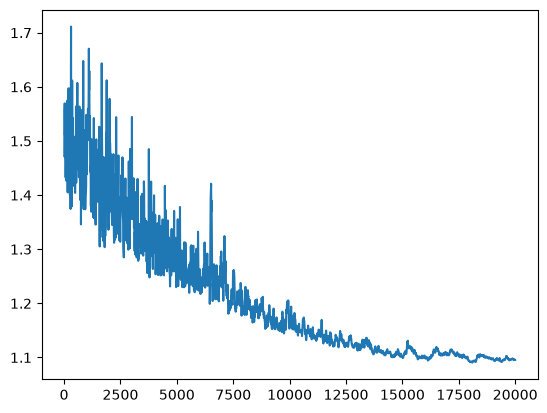

In [53]:
q_err = model.quantization_err
plt.plot(model.iter_steps, q_err)

<Axes: xlabel='feature1', ylabel='feature2'>

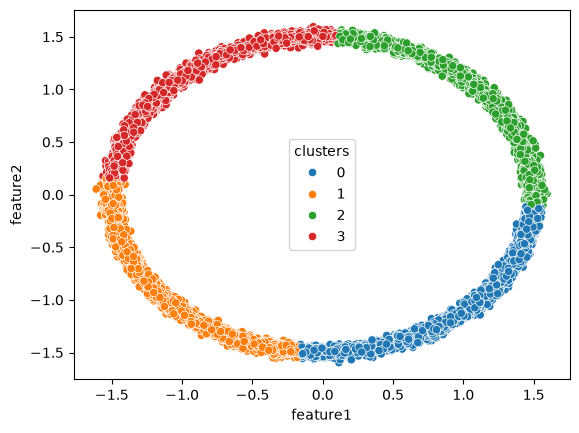

In [54]:
sns.scatterplot(data=df_c, x='feature1', y='feature2', hue='clusters', palette='tab10')

# Two Clusters Dataset

In [19]:
def make_clusters(centers, n_per, std):
    centers = torch.tensor(centers, dtype=torch.float32)        # (K, 2)
    K = centers.shape[0]
    labels = torch.arange(K).repeat_interleave(n_per)           # (K*n_per,)
    data = centers[labels] + std * torch.randn(K * n_per, 2)    # (K*n_per, 2)
    return data, labels

In [20]:

data2, labels2 = make_clusters([[-2, 0], [2, 0]], n_per=10000, std=0.3)

In [21]:
df_2 = pd.DataFrame(
    {
        'feature1' : data2[:,0],
        'feature2' : data2[:,1]
        }
)

<Axes: xlabel='feature1', ylabel='feature2'>

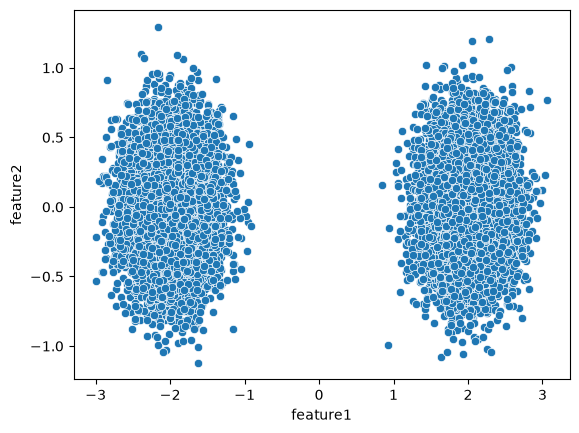

In [22]:
sns.scatterplot(data=df_2, x='feature1', y='feature2')

In [23]:
model = SelfOrganizingMaps(
    data = df_2,
    x_neuron=2,
    y_neuron=2,
    n_iter = 20000
)

In [24]:
model.fit_train()

In [25]:
bmu, index_bmu, lowest_d = model.predict()

In [32]:
df_2['clusters'] = index_bmu[:, 0]
df_2['distance_neuron_from_data'] = lowest_d[:, 0]

In [33]:
q_err = model.quantization_err

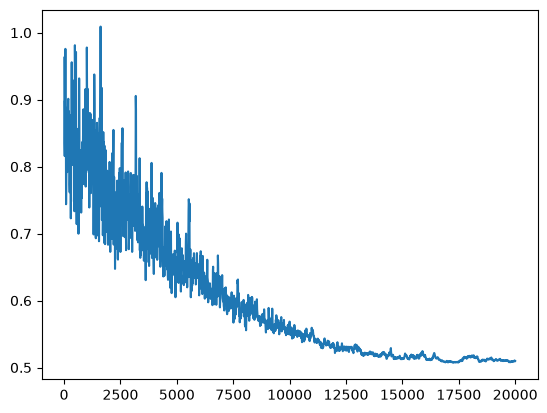

In [34]:
plt.plot(model.iter_steps, q_err)

<Axes: xlabel='feature1', ylabel='feature2'>

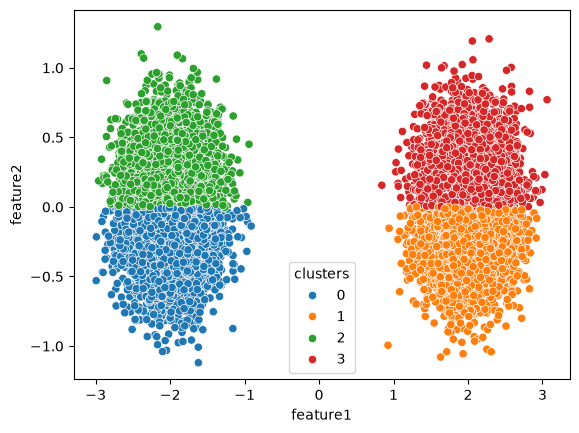

In [35]:
sns.scatterplot(data=df_2, x='feature1', y='feature2', hue='clusters', palette='tab10')

# Three Clusters Dataset

In [36]:
data3, labels3 = make_clusters([[-2, -1.5], [2, -1.5], [0, 2]], n_per=10000, std=0.3)

In [37]:
df_3 = pd.DataFrame(
    {
        'feature1' : data3[:,0],
        'feature2' : data3[:,1]
        }
)

<Axes: xlabel='feature1', ylabel='feature2'>

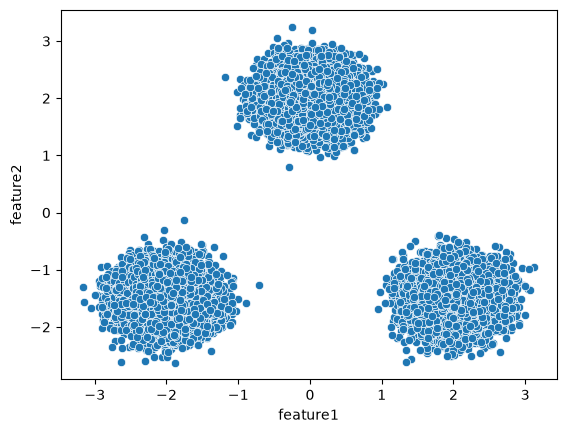

In [38]:
sns.scatterplot(data=df_3, x='feature1', y='feature2')

In [39]:
model = SelfOrganizingMaps(
    data = df_3,
    x_neuron=2,
    y_neuron=2,
    n_iter = 20000
)

In [40]:
model.fit_train()

In [41]:
bmu, index_bmu, lowest_d = model.predict()

In [42]:
df_3['neuron'] = index_bmu[:, 0]
df_3['distance_neuron_from_data'] = lowest_d[:, 0]

In [43]:
df_3.head()

,feature1,feature2,neuron,distance_neuron_from_data
0,-2.785564,-1.386258,2,0.487437
1,-1.626131,-1.435335,2,0.216048
2,-2.218591,-1.554323,2,0.148986
3,-2.675567,-1.122810,2,0.469413
4,-2.356665,-0.962871,2,0.382839


In [44]:
q_err = model.quantization_err

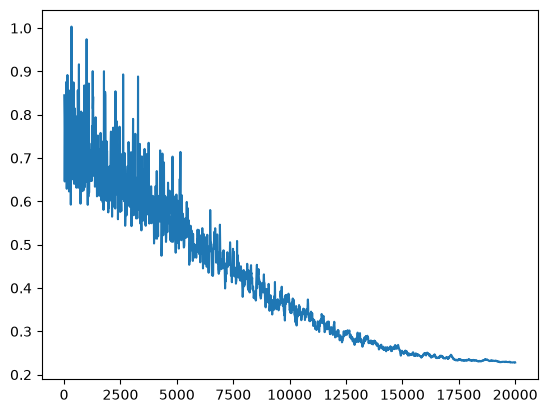

In [45]:
plt.plot(model.iter_steps, q_err)

<Axes: xlabel='feature1', ylabel='feature2'>

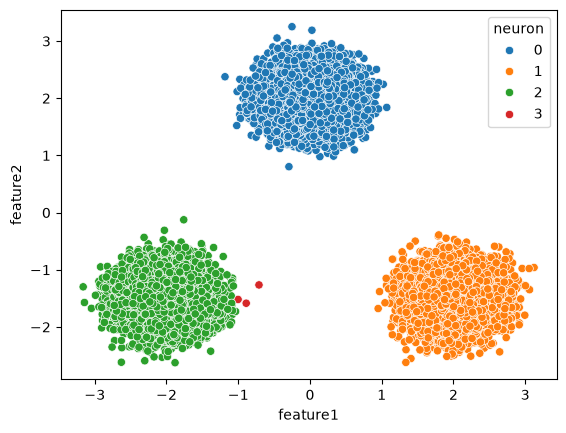

In [46]:
sns.scatterplot(data=df_3, x='feature1', y='feature2', hue='neuron', palette='tab10')